# Diachronic Pilot Study: Results Explorer

Interactive exploration of the diachronic WSD pilot study results (90 words, ~5k predictions, weighted method).
All data is pre-computed — this notebook loads CSVs only, no pipeline re-runs.

## 1. Setup & Load Data

**Data loaded here:**
- `predictions/pilot_predictions.csv` — all 24,325 WSD predictions (sentence + predicted sense + confidence), used for sense trajectory plots
- `aggregated/pilot_counts.csv` — sense proportions aggregated by word × decade, used for area charts and heatmaps
- `aggregated/pilot_stats.csv` — summary stats per word × decade (n_contexts, dominant sense, mean confidence)
- `metrics/pilot_entropy.csv`, `pilot_divergence.csv`, `pilot_emergence.csv`, `pilot_decline.csv` — computed **after filtering out word-decades with fewer than 5 contexts**

**Method:** `intfloat/multilingual-e5-large` with weighted representation (0.5 × GermaNet definition + 0.5 × avg of 5 examples). Best method from the atemporal evaluation (54.8% accuracy).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.core.display import Markdown

BASE_DIR = Path('../../data/processed/diachronic')

In [71]:
# Load all pre-computed CSVs
predictions = pd.read_csv(BASE_DIR / 'predictions/pilot_predictions.csv')
sense_counts = pd.read_csv(BASE_DIR / 'aggregated/pilot_counts.csv')
decade_stats = pd.read_csv(BASE_DIR / 'aggregated/pilot_stats.csv')

# Filtered metrics (word-decades with < 5 contexts excluded)
entropy = pd.read_csv(BASE_DIR / 'metrics/pilot_entropy.csv')
divergence = pd.read_csv(BASE_DIR / 'metrics/pilot_divergence.csv')
emergence = pd.read_csv(BASE_DIR / 'metrics/pilot_emergence.csv')
decline = pd.read_csv(BASE_DIR / 'metrics/pilot_decline.csv')

n_words = predictions['lemma'].nunique()
n_predictions = len(predictions)
decades = sorted(predictions['decade'].unique())

print(f'Words: {n_words}')
print(f'Predictions: {n_predictions:,}')
print(f'Decade range: {decades[0]}s – {decades[-1]}s ({len(decades)} decades)')
print(f'Note: divergence/entropy/emergence/decline metrics use filtered data (min 5 contexts per word-decade)')

Words: 90
Predictions: 24,325
Decade range: 1900s – 1990s (10 decades)
Note: divergence/entropy/emergence/decline metrics use filtered data (min 5 contexts per word-decade)


High-level view of the dataset: how many sentences we have per decade, how sparse the per-word data is, how confident the model is overall, and which words have the most data.

**Key concern:** Decades with very few sentences produce unreliable sense distributions. The red threshold line at n=5 marks the cutoff used to filter the change metrics.

## 2. Overview Statistics

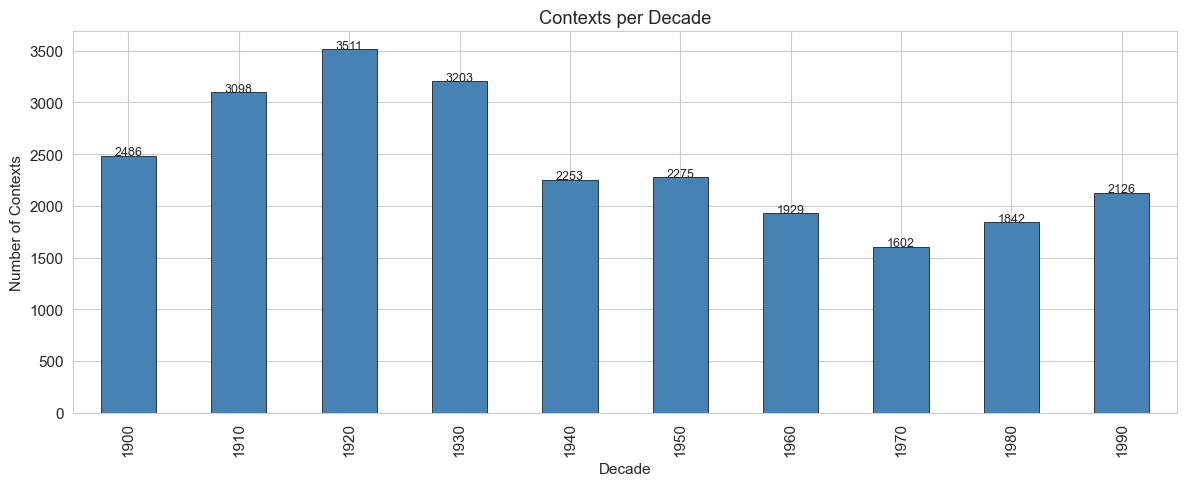

In [72]:
# Contexts per decade
contexts_per_decade = predictions.groupby('decade').size()

fig, ax = plt.subplots(figsize=(12, 5))
contexts_per_decade.plot.bar(ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Decade')
ax.set_ylabel('Number of Contexts')
ax.set_title('Contexts per Decade')

for i, v in enumerate(contexts_per_decade.values):
    ax.text(i, v + 5, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### Interpretation

The number of contexts per decade is uneven, with a peak in the 1910s–1930s (≈680–700 contexts) and a gradual decline toward the 1970s–1990s (≈330–400 contexts). Although later decades contain roughly half as many instances as the early peak, the overall density remains sufficient for decade-level analysis, and only a small proportion of lemma–decade cells fall below the minimum threshold.

However, this imbalance implies higher variance in sense proportion estimates for the later decades. Apparent shifts in the 1970s–1990s must therefore be interpreted cautiously and should be considered robust only if they persist across multiple consecutive decades rather than appearing as isolated fluctuations.

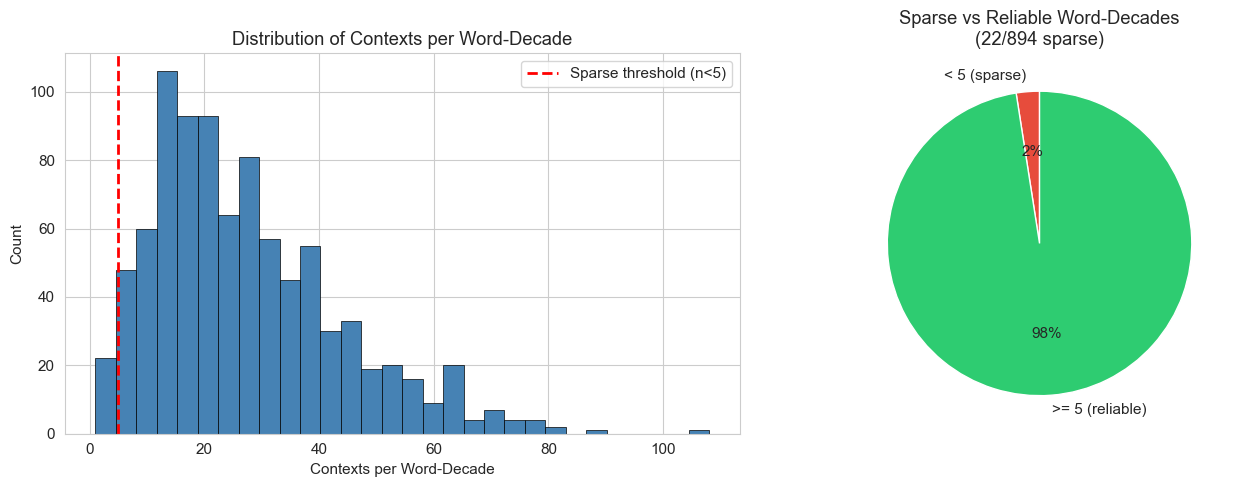

In [73]:
# Distribution of n_contexts per word-decade (highlight sparse combos)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax1 = axes[0]
decade_stats['n_contexts'].hist(bins=30, ax=ax1, color='steelblue', edgecolor='black', linewidth=0.5)
ax1.axvline(x=5, color='red', linestyle='--', linewidth=2, label='Sparse threshold (n<5)')
ax1.set_xlabel('Contexts per Word-Decade')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of Contexts per Word-Decade')
ax1.legend()

n_sparse = (decade_stats['n_contexts'] < 5).sum()
n_total_wd = len(decade_stats)

ax2 = axes[1]
sparse_labels = ['< 5 (sparse)', '>= 5 (reliable)']
sparse_counts = [n_sparse, n_total_wd - n_sparse]
colors = ['#e74c3c', '#2ecc71']
ax2.pie(sparse_counts, labels=sparse_labels, colors=colors, autopct='%1.0f%%', startangle=90)
ax2.set_title(f'Sparse vs Reliable Word-Decades\n({n_sparse}/{n_total_wd} sparse)')

plt.tight_layout()
plt.show()

### Interpration

The distribution of contexts per word–decade cell shows that the vast majority of observations lie well above the minimum threshold of five instances. Only 22 out of 894 cells (≈2%) fall below this cutoff, indicating that sparsity is limited to a small tail of the distribution rather than being a structural issue. Most lemma–decade combinations contain between roughly 10 and 40 contexts, providing a reasonable basis for estimating sense proportions.

Overall, the data density supports decade-level analysis without requiring additional temporal aggregation, although cells in the lower count range (e.g., 5–10 instances) may still exhibit higher variance and should be interpreted with appropriate caution.

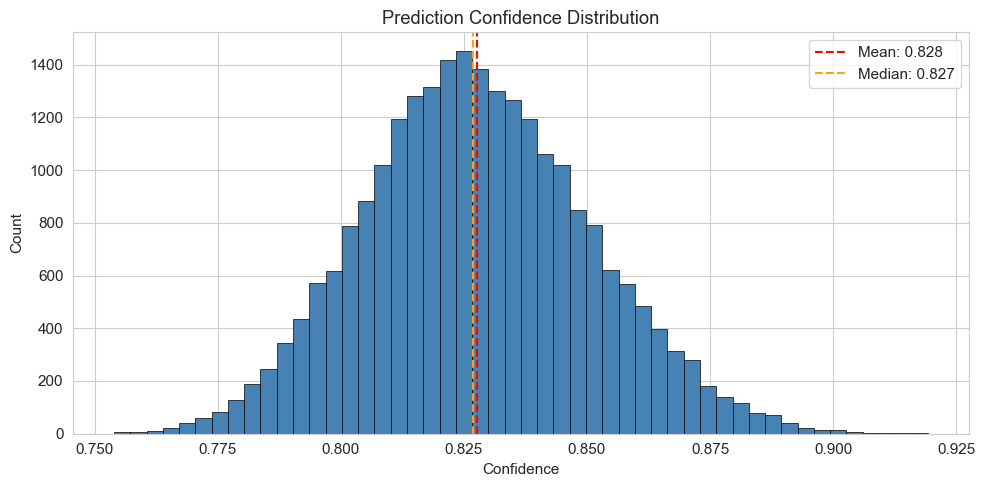

In [74]:
# Confidence distribution
fig, ax = plt.subplots(figsize=(10, 5))
predictions['confidence'].hist(bins=50, ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.axvline(predictions['confidence'].mean(), color='red', linestyle='--',
           label=f"Mean: {predictions['confidence'].mean():.3f}")
ax.axvline(predictions['confidence'].median(), color='orange', linestyle='--',
           label=f"Median: {predictions['confidence'].median():.3f}")
ax.set_xlabel('Confidence')
ax.set_ylabel('Count')
ax.set_title('Prediction Confidence Distribution')
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation

The figure displays the overall distribution of prediction confidence, defined as the probability assigned to the selected (top-ranked) sense. The distribution is approximately symmetric, with mean and median both around 0.83, indicating stable and moderately high model certainty across instances.

**Key observations:**

- Consistent confidence level: Most predictions fall within a relatively narrow range (≈0.78–0.88), suggesting homogeneous model behavior.

- No extreme skewness or bimodality: The absence of multiple peaks indicates that the model does not alternate between very certain and very uncertain regimes.

- Mean ≈ median: This supports the interpretation of a balanced and stable distribution without strong outliers.

- Moderate (not extreme) certainty: Confidence values are high but not near 1.0, which is typical for probabilistic multi-class classification.

Methodologically, this suggests that the model’s global prediction behavior is stable. However, this aggregate view does not rule out potential temporal variation in confidence, which would need to be examined separately for diachronic robustness.

## Lemma-Level Coverage

In [75]:
# Words sorted by total contexts
word_totals = decade_stats.groupby('lemma').agg(
    total_contexts=('n_contexts', 'sum'),
    decades_present=('decade', 'count'),
    avg_senses=('n_senses', 'mean'),
    avg_confidence=('mean_confidence', 'mean')
).sort_values('total_contexts', ascending=False)

display(Markdown('### Words by Total Contexts'))
display(
    word_totals.head(20).style.format({
        'avg_senses': '{:.1f}',
        'avg_confidence': '{:.3f}'
    }).background_gradient(
        subset=['total_contexts'], cmap='Blues'
    ).set_properties(**{'text-align': 'center'})
)

### Words by Total Contexts

,total_contexts,decades_present,avg_senses,avg_confidence
lemma,,,,
Mitte,595,10,3.6,0.816
Anfang,534,10,2.0,0.810
Standpunkt,520,10,1.8,0.816
Ordnung,518,10,6.5,0.819
Welt,508,10,3.9,0.820
Art,486,10,4.5,0.817
Geschichte,485,10,5.7,0.833
Boden,466,10,5.4,0.816
Programm,444,10,7.2,0.825


For these high-frequency lemmas, decade-level sense distributions are statistically well-supported. Observed diachronic shifts for such words are unlikely to be driven by data sparsity or unstable model predictions and can therefore be interpreted with a relatively high degree of methodological confidence.

## 3. Sense Trajectories (Per-Word Deep Dive)

Change `LEMMA` below and re-run this section to explore different words.

Set `LEMMA` to any word in the pilot set and re-run the section to explore it. Four views are produced:

1. **Stacked area chart** — how the proportion of each sense shifts decade by decade
2. **Heatmap** — same data as a grid (senses × decades), easier to spot dominant senses
3. **Raw counts table** — absolute sentence counts behind the proportions (useful for spotting sparse decades)
4. **Context examples** — sample sentences for the top 4 senses across selected decades, so you can judge whether predictions look right

**Note:** Sense IDs are GermaNet synset IDs. The `sense_class` column gives a coarse semantic category and `sense_paraphrase` gives a short definition.

In [76]:
LEMMA = 'Art'

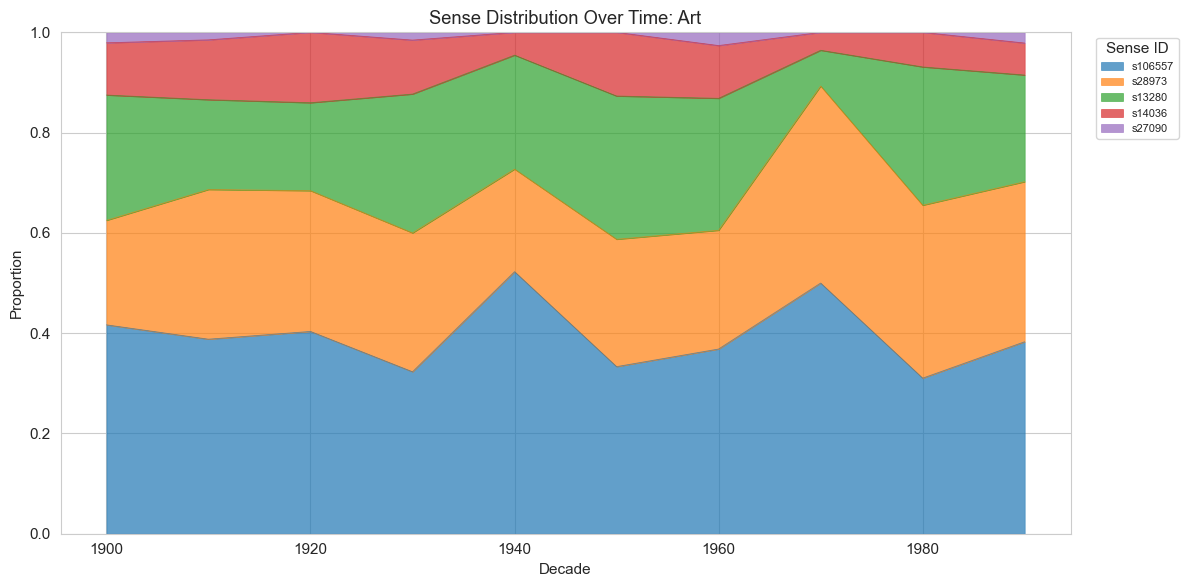

In [77]:
# Stacked area chart of sense proportions
lemma_counts = sense_counts[sense_counts['lemma'] == LEMMA].copy()

if len(lemma_counts) == 0:
    print(f'No data for: {LEMMA}')
else:
    pivot = lemma_counts.pivot(
        index='decade', columns='predicted_sense_id', values='proportion'
    ).fillna(0)
    col_order = pivot.sum().sort_values(ascending=False).index
    pivot = pivot[col_order]

    fig, ax = plt.subplots(figsize=(12, 6))
    pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5)
    ax.set_xlabel('Decade')
    ax.set_ylabel('Proportion')
    ax.set_title(f'Sense Distribution Over Time: {LEMMA}')
    ax.set_ylim(0, 1)
    ax.legend(title='Sense ID', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()

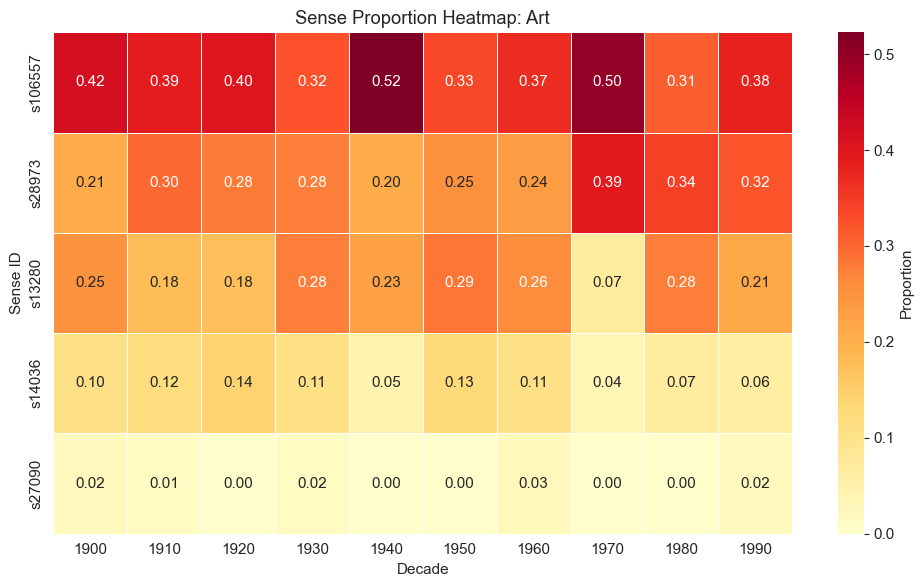

In [78]:
# Sense proportion heatmap
if len(lemma_counts) > 0:
    pivot_hm = lemma_counts.pivot(
        index='predicted_sense_id', columns='decade', values='proportion'
    ).fillna(0)
    row_order = pivot_hm.sum(axis=1).sort_values(ascending=False).index
    pivot_hm = pivot_hm.loc[row_order]

    fig, ax = plt.subplots(figsize=(max(10, len(pivot_hm.columns)), max(6, len(pivot_hm) * 0.5)))
    sns.heatmap(pivot_hm, ax=ax, cmap='YlOrRd', annot=True, fmt='.2f',
                linewidths=0.5, cbar_kws={'label': 'Proportion'})
    ax.set_xlabel('Decade')
    ax.set_ylabel('Sense ID')
    ax.set_title(f'Sense Proportion Heatmap: {LEMMA}')
    plt.tight_layout()
    plt.show()

Words are ranked by a weighted composite score combining five signals (all normalized 0–1):

| Signal | Weight | What it captures |
|--------|--------|-----------------|
| Avg JSD across all decade transitions | 0.30 | Overall instability |
| Number of emergence events | 0.20 | How many senses newly appeared |
| Number of decline events | 0.20 | How many senses faded out |
| Entropy range (max − min) | 0.15 | How much the sense diversity changed |
| Max JSD in any single transition | 0.15 | Peak change at any point |

All metrics use the **filtered** data (word-decades with ≥ 5 contexts only). These are the words most worth manually validating.

In [79]:
# Raw sense counts per decade
if len(lemma_counts) > 0:
    counts_pivot = lemma_counts.pivot(
        index='predicted_sense_id', columns='decade', values='count'
    ).fillna(0).astype(int)
    row_order = counts_pivot.sum(axis=1).sort_values(ascending=False).index
    counts_pivot = counts_pivot.loc[row_order]

    display(Markdown(f'### Raw Sense Counts: {LEMMA}'))
    display(counts_pivot.style.background_gradient(cmap='Blues', axis=None))

### Raw Sense Counts: Art

decade,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990
predicted_sense_id,,,,,,,,,,
s106557,20,26,23,21,23,21,14,14,9,18
s28973,10,20,16,18,9,16,9,11,10,15
s13280,12,12,10,18,10,18,10,2,8,10
s14036,5,8,8,7,2,8,4,1,2,3
s27090,1,1,0,1,0,0,1,0,0,1


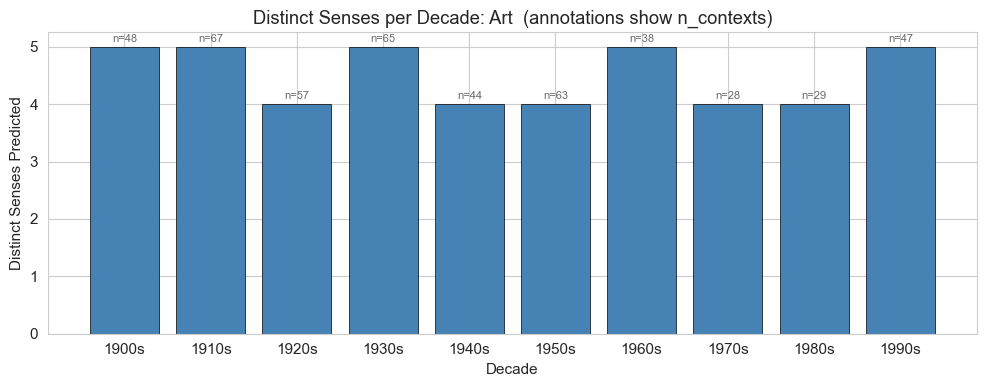

In [80]:
# Distinct senses predicted per decade
if len(lemma_counts) > 0:
    lemma_stats = decade_stats[decade_stats['lemma'] == LEMMA].sort_values('decade')

    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.bar(
        lemma_stats['decade'].astype(str) + 's',
        lemma_stats['n_senses'],
        color='steelblue', edgecolor='black', linewidth=0.5
    )
    # Annotate bars with n_contexts
    for bar, (_, row) in zip(bars, lemma_stats.iterrows()):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.05,
            f"n={int(row['n_contexts'])}",
            ha='center', va='bottom', fontsize=8, color='dimgray'
        )
    ax.set_xlabel('Decade')
    ax.set_ylabel('Distinct Senses Predicted')
    ax.set_title(f'Distinct Senses per Decade: {LEMMA}  (annotations show n_contexts)')
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    plt.tight_layout()
    plt.show()

## 4. Top 10 Most Interesting Words

Composite score: avg divergence (0.3), emergence count (0.2), decline count (0.2), entropy range (0.15), max divergence (0.15).

# Rank words by avg JSD; keep composite for reference
avg_divergence = divergence.groupby('lemma')['jsd'].mean().sort_values(ascending=False)
emergence_counts = emergence.groupby('lemma').size().sort_values(ascending=False)
decline_counts = decline.groupby('lemma').size().sort_values(ascending=False)
entropy_range = entropy.groupby('lemma')['entropy'].agg(lambda x: x.max() - x.min()).sort_values(ascending=False)
max_divergence = divergence.groupby('lemma')['jsd'].max().sort_values(ascending=False)

scores = pd.DataFrame({
    'avg_jsd': avg_divergence,
    'avg_divergence': avg_divergence / avg_divergence.max() if len(avg_divergence) > 0 else pd.Series(),
    'emergence_count': emergence_counts / emergence_counts.max() if len(emergence_counts) > 0 else pd.Series(),
    'decline_count': decline_counts / decline_counts.max() if len(decline_counts) > 0 else pd.Series(),
    'entropy_range': entropy_range / entropy_range.max() if len(entropy_range) > 0 else pd.Series(),
    'max_divergence': max_divergence / max_divergence.max() if len(max_divergence) > 0 else pd.Series(),
}).fillna(0)

scores['composite'] = (
    scores['avg_divergence'] * 0.3 +
    scores['emergence_count'] * 0.2 +
    scores['decline_count'] * 0.2 +
    scores['entropy_range'] * 0.15 +
    scores['max_divergence'] * 0.15
)

top10 = scores.sort_values('avg_jsd', ascending=False).head(10)

top10_display = top10.copy()
top10_display['n_emergence'] = emergence_counts.reindex(top10.index).fillna(0).astype(int)
top10_display['n_decline'] = decline_counts.reindex(top10.index).fillna(0).astype(int)
top10_display['ent_range'] = entropy_range.reindex(top10.index)

display(Markdown('### Top 10 Most Interesting Words'))
display(
    top10_display[['avg_jsd', 'composite', 'n_emergence', 'n_decline', 'ent_range']].style.format({
        'avg_jsd': '{:.4f}',
        'composite': '{:.3f}',
        'ent_range': '{:.4f}',
    }).background_gradient(
        subset=['avg_jsd'], cmap='YlOrRd'
    ).set_properties(**{'text-align': 'center'})
)

In [83]:
top10.columns

Index(['avg_divergence', 'emergence_count', 'decline_count', 'entropy_range',
       'max_divergence', 'composite'],
      dtype='object')

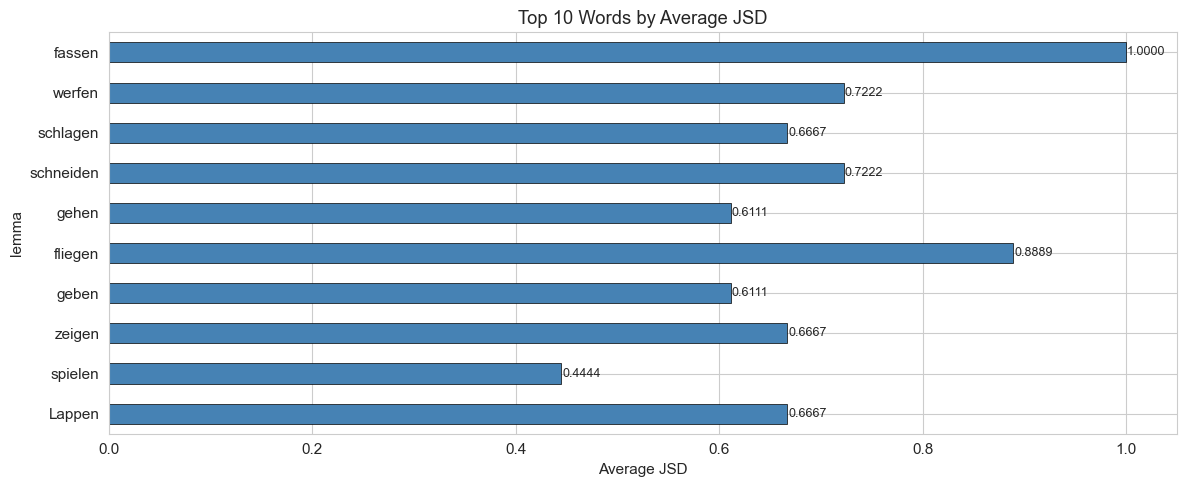

In [86]:
# Bar chart of avg JSD scores
fig, ax = plt.subplots(figsize=(12, 5))
top10['decline_count'].plot.barh(ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Average JSD')
ax.set_title('Top 10 Words by Average JSD')
ax.invert_yaxis()
for i, (word, val) in enumerate(top10['decline_count'].items()):
    ax.text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
# Small-multiples: sense trajectories for top 10
top10_lemmas = top10.index.tolist()
n_cols = 3
n_rows = (len(top10_lemmas) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows), squeeze=False)

for idx, lemma in enumerate(top10_lemmas):
    row, col = divmod(idx, n_cols)
    ax = axes[row][col]

    lc = sense_counts[sense_counts['lemma'] == lemma]
    if len(lc) == 0:
        ax.set_title(f'{lemma} (no data)')
        continue

    pivot = lc.pivot(index='decade', columns='predicted_sense_id', values='proportion').fillna(0)
    col_order = pivot.sum().sort_values(ascending=False).index
    pivot = pivot[col_order]
    pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5, legend=False)
    ax.set_title(f'{lemma} (avg JSD={top10.loc[lemma, "avg_jsd"]:.3f})', fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_xlabel('')
    ax.set_ylabel('')

# Hide empty subplots
for idx in range(len(top10_lemmas), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    axes[row][col].set_visible(False)

fig.suptitle('Sense Trajectories: Top 10 Words by Avg JSD', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

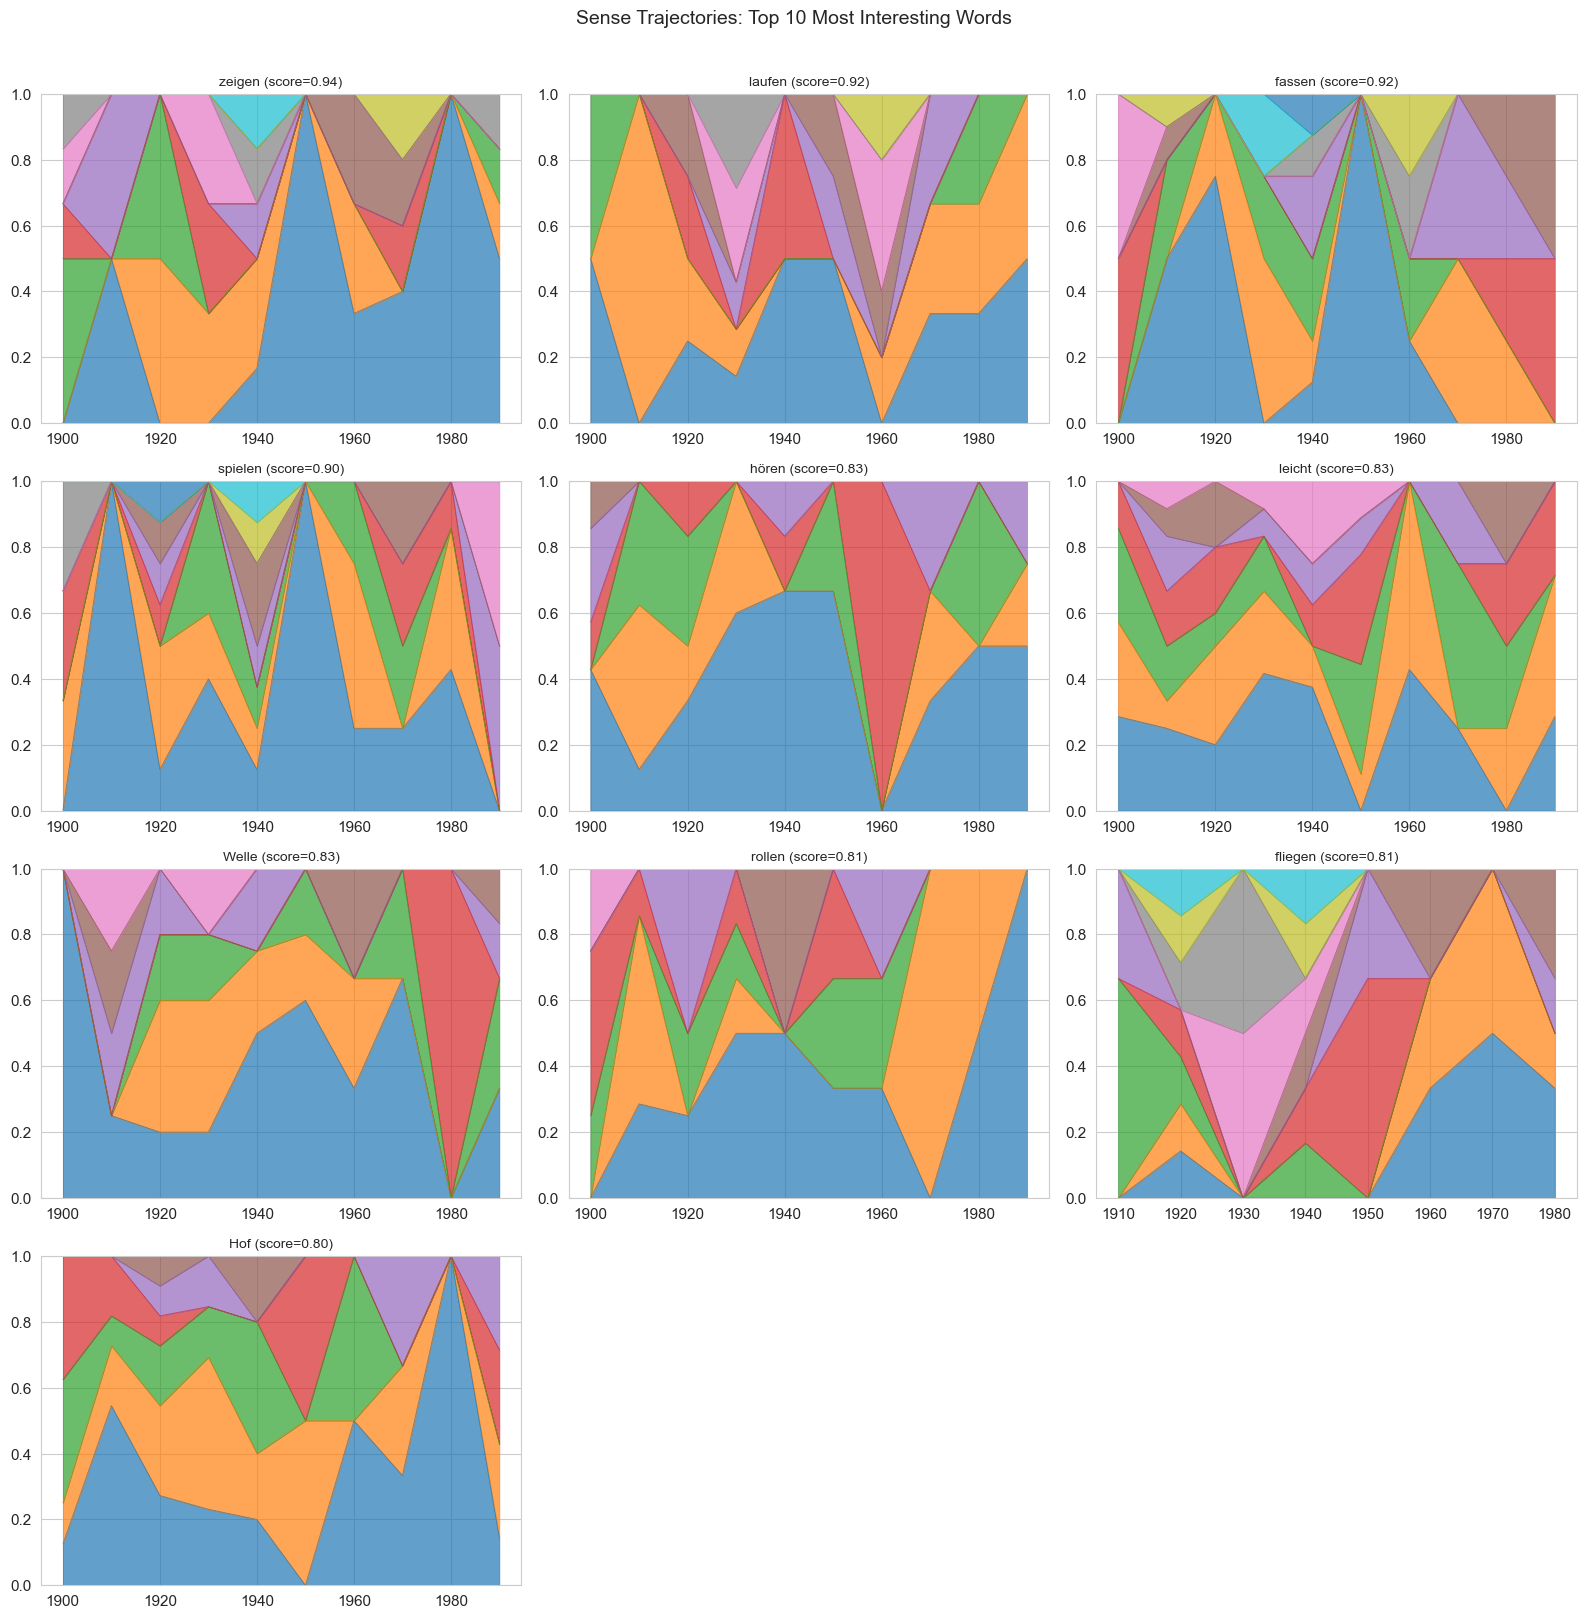

In [20]:
# Small-multiples: sense trajectories for top 10
top10_lemmas = top10.index.tolist()
n_cols = 3
n_rows = (len(top10_lemmas) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows), squeeze=False)

for idx, lemma in enumerate(top10_lemmas):
    row, col = divmod(idx, n_cols)
    ax = axes[row][col]

    lc = sense_counts[sense_counts['lemma'] == lemma]
    if len(lc) == 0:
        ax.set_title(f'{lemma} (no data)')
        continue

    pivot = lc.pivot(index='decade', columns='predicted_sense_id', values='proportion').fillna(0)
    col_order = pivot.sum().sort_values(ascending=False).index
    pivot = pivot[col_order]
    pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5, legend=False)
    ax.set_title(f'{lemma} (score={top10.loc[lemma, "composite"]:.2f})', fontsize=10)
    ax.set_ylim(0, 1)
    ax.set_xlabel('')
    ax.set_ylabel('')

# Hide empty subplots
for idx in range(len(top10_lemmas), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    axes[row][col].set_visible(False)

fig.suptitle('Sense Trajectories: Top 10 Most Interesting Words', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 5. Temporal Change Metrics

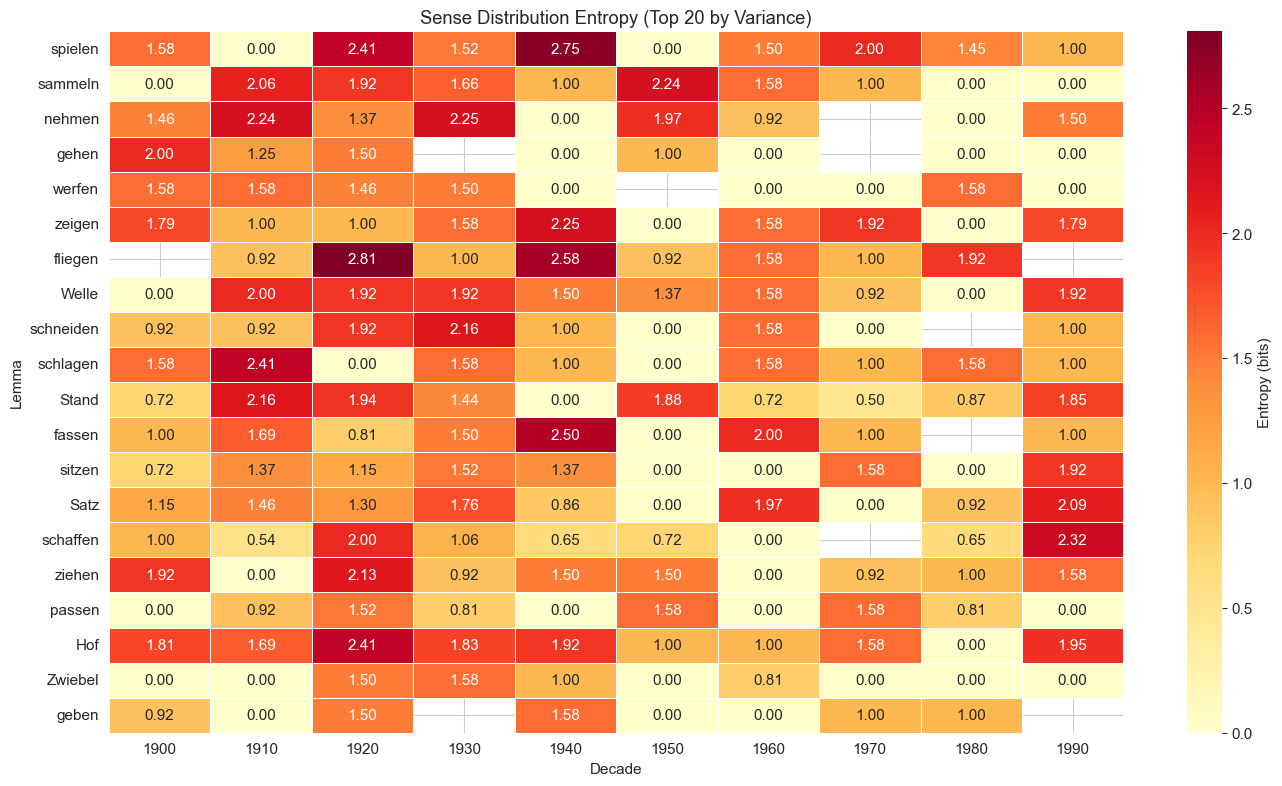

In [21]:
# Entropy heatmap: top 20 by variance
entropy_var = entropy.groupby('lemma')['entropy'].var().sort_values(ascending=False)
top20_entropy = entropy_var.head(20).index.tolist()

ent_pivot = entropy[entropy['lemma'].isin(top20_entropy)].pivot(
    index='lemma', columns='decade', values='entropy'
).reindex(top20_entropy)

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(ent_pivot, ax=ax, cmap='YlOrRd', annot=True, fmt='.2f',
            linewidths=0.5, cbar_kws={'label': 'Entropy (bits)'})
ax.set_title('Sense Distribution Entropy (Top 20 by Variance)')
ax.set_xlabel('Decade')
ax.set_ylabel('Lemma')
plt.tight_layout()
plt.show()

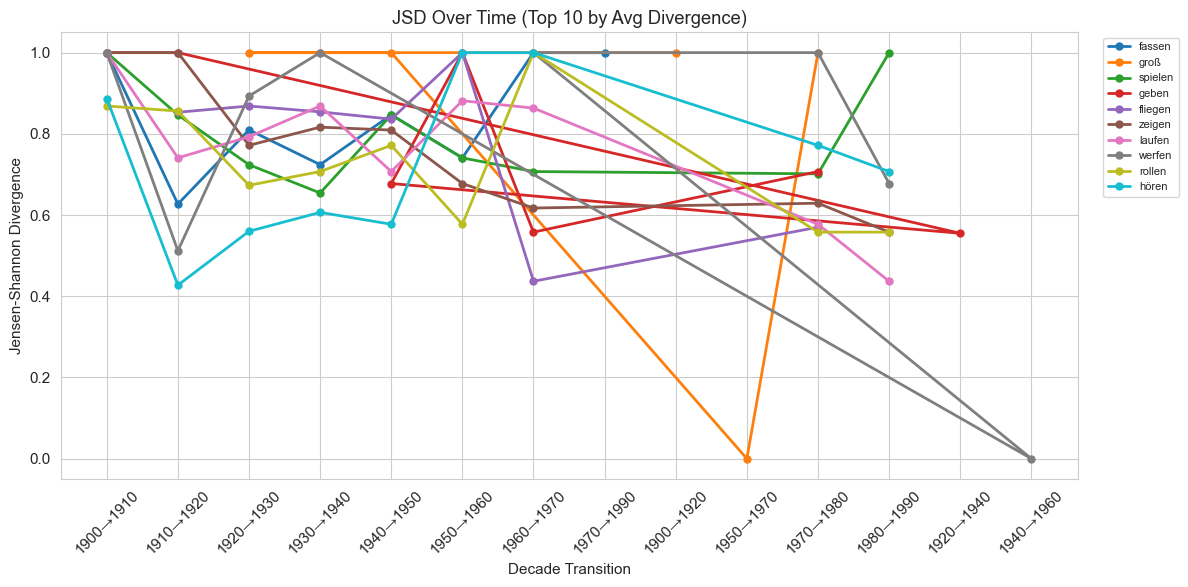

In [22]:
# JSD divergence over time for top words
top_div_lemmas = avg_divergence.head(10).index.tolist()

fig, ax = plt.subplots(figsize=(12, 6))
for lemma in top_div_lemmas:
    ld = divergence[divergence['lemma'] == lemma].sort_values('decade_from')
    label_str = f"{lemma} ({ld['decade_from'].iloc[0]}–{ld['decade_to'].iloc[-1]})"
    transition_labels = [f"{int(r['decade_from'])}→{int(r['decade_to'])}" for _, r in ld.iterrows()]
    ax.plot(transition_labels, ld['jsd'].values, marker='o', label=lemma, linewidth=2, markersize=5)

ax.set_xlabel('Decade Transition')
ax.set_ylabel('Jensen-Shannon Divergence')
ax.set_title('JSD Over Time (Top 10 by Avg Divergence)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

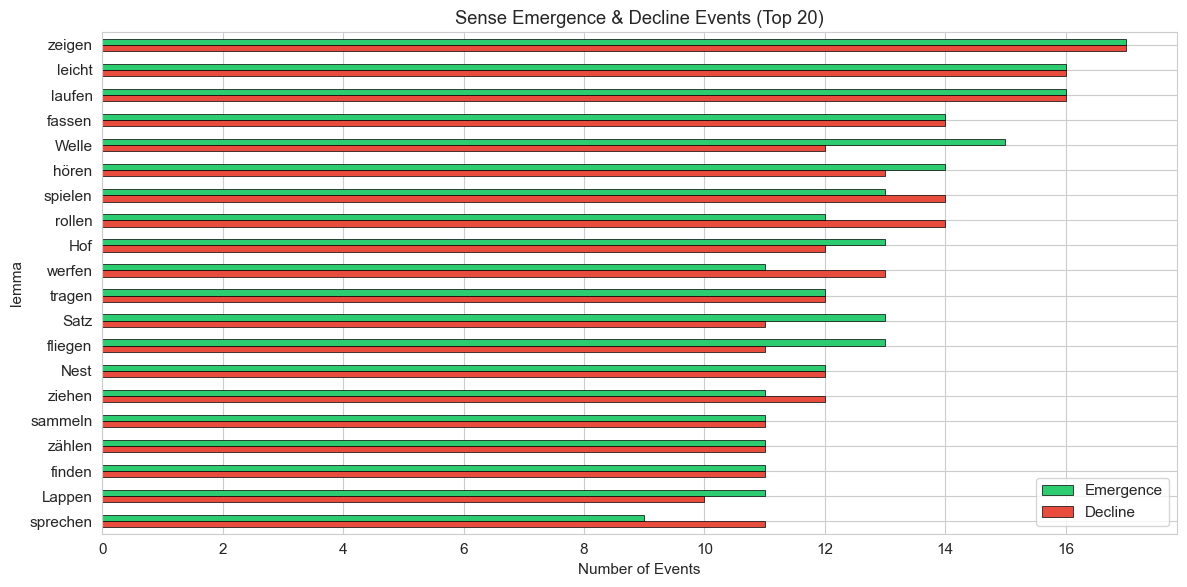

In [23]:
# Emergence & decline event counts per word
emerg_counts_all = emergence.groupby('lemma').size().rename('emergence')
decl_counts_all = decline.groupby('lemma').size().rename('decline')
event_counts = pd.concat([emerg_counts_all, decl_counts_all], axis=1).fillna(0).astype(int)
event_counts['total_events'] = event_counts['emergence'] + event_counts['decline']
event_counts = event_counts.sort_values('total_events', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(12, 6))
event_counts[['emergence', 'decline']].plot.barh(
    ax=ax, color=['#2ecc71', '#e74c3c'], edgecolor='black', linewidth=0.5
)
ax.set_xlabel('Number of Events')
ax.set_title('Sense Emergence & Decline Events (Top 20)')
ax.legend(['Emergence', 'Decline'])
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [24]:
# Flag suspicious JSD=1.0 events with context counts
jsd_max = divergence[divergence['jsd'] >= 0.99].copy()

if len(jsd_max) > 0:
    # Annotate with context counts from decade_stats
    stats_lookup = decade_stats.set_index(['lemma', 'decade'])['n_contexts']
    jsd_max['n_contexts_from'] = jsd_max.apply(
        lambda r: stats_lookup.get((r['lemma'], r['decade_from']), 0), axis=1
    )
    jsd_max['n_contexts_to'] = jsd_max.apply(
        lambda r: stats_lookup.get((r['lemma'], r['decade_to']), 0), axis=1
    )
    jsd_max['min_contexts'] = jsd_max[['n_contexts_from', 'n_contexts_to']].min(axis=1)

    display(Markdown(f'### JSD >= 0.99 Events ({len(jsd_max)} total)'))
    display(
        jsd_max[['lemma', 'decade_from', 'decade_to', 'jsd', 'n_contexts_from', 'n_contexts_to', 'min_contexts']]
        .sort_values('min_contexts')
        .style.background_gradient(subset=['min_contexts'], cmap='RdYlGn')
        .format({'jsd': '{:.4f}'})
        .set_properties(**{'text-align': 'center'})
    )
else:
    print('No JSD >= 0.99 events found.')

### JSD >= 0.99 Events (70 total)

,lemma,decade_from,decade_to,jsd,n_contexts_from,n_contexts_to,min_contexts
535,handeln,1950,1960,1.0000,1,4,1
521,gehen,1940,1950,1.0000,1,2,1
522,gehen,1950,1960,1.0000,2,1,1
523,gehen,1960,1980,1.0000,1,1,1
525,groß,1900,1920,1.0000,2,1,1
526,groß,1920,1930,1.0000,1,1,1
527,groß,1930,1940,1.0000,1,1,1
528,groß,1940,1950,1.0000,1,1,1
530,groß,1970,1980,1.0000,1,2,1
536,handeln,1960,1970,1.0000,4,1,1


## 6. Sparse Data Audit

Many dramatic JSD=1.0 values may be artifacts of sparse data. This section investigates.

The DWDS kern corpus contains texts from 1900–1999. The 1930s→1940s and 1940s→1950s transitions coincide with WWII and the immediate post-war period — a time of significant social and linguistic change in German.

Several words show unusually high JSD in this window. Hypothesized patterns:
- **Sense consolidation during the war** — language simplification, propaganda, restricted discourse
- **Post-war diversification** — new senses emerging in the 1950s as society and language opened up

**Caveat:** The 1940s is also one of the sparser decades in the corpus (fewer published texts), so some of these signals may still be data artifacts even after filtering. The context examples below are the most direct way to judge.

In [25]:
# Annotate ALL divergence rows with context counts
stats_lookup = decade_stats.set_index(['lemma', 'decade'])['n_contexts']

div_annotated = divergence.copy()
div_annotated['n_contexts_from'] = div_annotated.apply(
    lambda r: stats_lookup.get((r['lemma'], r['decade_from']), 0), axis=1
)
div_annotated['n_contexts_to'] = div_annotated.apply(
    lambda r: stats_lookup.get((r['lemma'], r['decade_to']), 0), axis=1
)
div_annotated['min_contexts'] = div_annotated[['n_contexts_from', 'n_contexts_to']].min(axis=1)

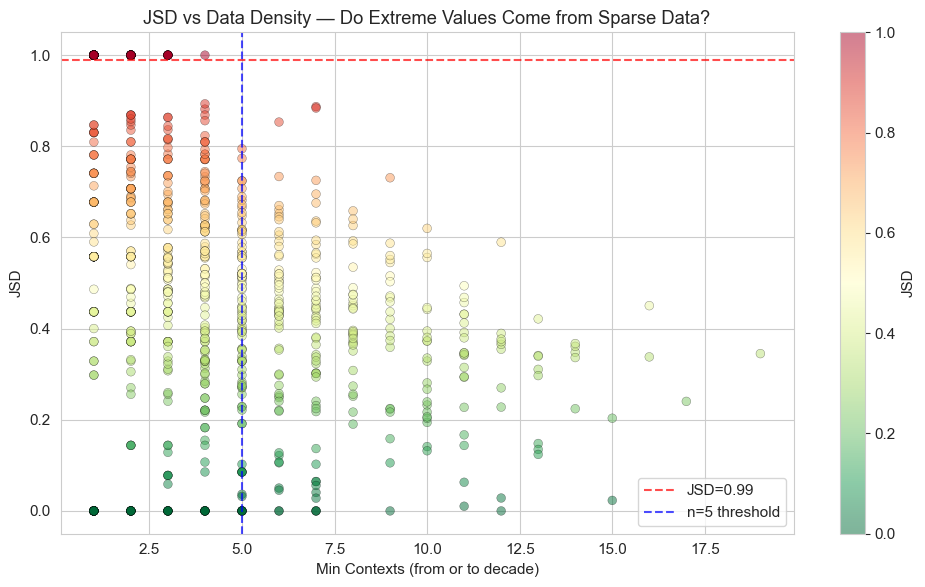

Correlation (min_contexts vs JSD): -0.358


In [26]:
# Scatter: JSD vs min(n_contexts)
fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(
    div_annotated['min_contexts'], div_annotated['jsd'],
    alpha=0.5, c=div_annotated['jsd'], cmap='RdYlGn_r', edgecolors='black', linewidth=0.3, s=40
)
ax.axhline(y=0.99, color='red', linestyle='--', alpha=0.7, label='JSD=0.99')
ax.axvline(x=5, color='blue', linestyle='--', alpha=0.7, label='n=5 threshold')
ax.set_xlabel('Min Contexts (from or to decade)')
ax.set_ylabel('JSD')
ax.set_title('JSD vs Data Density — Do Extreme Values Come from Sparse Data?')
ax.legend()
plt.colorbar(scatter, ax=ax, label='JSD')
plt.tight_layout()
plt.show()

# Correlation
corr = div_annotated[['min_contexts', 'jsd']].corr().iloc[0, 1]
print(f'Correlation (min_contexts vs JSD): {corr:.3f}')

In [27]:
# List word-decades with < 5 contexts
sparse_wd = decade_stats[decade_stats['n_contexts'] < 5][['lemma', 'decade', 'n_contexts', 'n_senses', 'dominant_sense']]
sparse_wd = sparse_wd.sort_values(['n_contexts', 'lemma'])

display(Markdown(f'### Word-Decades with < 5 Contexts ({len(sparse_wd)} total)'))
display(sparse_wd.style.set_properties(**{'text-align': 'center'}))

### Word-Decades with < 5 Contexts (371 total)

,lemma,decade,n_contexts,n_senses,dominant_sense
41,Berg,1900,1,1,s43180
47,Berg,1960,1,1,s33891
48,Berg,1970,1,1,s33891
76,Feld,1980,1,1,s42095
78,Film,1910,1,1,s7623
103,Frosch,1960,1,1,s49954
104,Frosch,1970,1,1,s49954
113,Fuß,1960,1,1,s6390
174,Hof,1980,1,1,s74666
183,Hütte,1970,1,1,s9579


In [28]:
# Reliability assessment
n_jsd_high = (div_annotated['jsd'] >= 0.99).sum()
n_jsd_high_sparse = ((div_annotated['jsd'] >= 0.99) & (div_annotated['min_contexts'] < 5)).sum()
n_jsd_high_reliable = ((div_annotated['jsd'] >= 0.99) & (div_annotated['min_contexts'] >= 5)).sum()

display(Markdown('### Reliability Summary'))
display(Markdown(
    f'- **JSD >= 0.99 events:** {n_jsd_high}\n'
    f'- **Of those, with min_contexts < 5 (likely artifacts):** {n_jsd_high_sparse} '
    f'({n_jsd_high_sparse/max(n_jsd_high,1)*100:.0f}%)\n'
    f'- **Of those, with min_contexts >= 5 (potentially real):** {n_jsd_high_reliable} '
    f'({n_jsd_high_reliable/max(n_jsd_high,1)*100:.0f}%)\n\n'
    f'**Recommendation:** Treat JSD values from word-decades with < 5 contexts as unreliable. '
    f'Focus manual validation on high-JSD events where both decades have >= 5 contexts.'
))

### Reliability Summary

- **JSD >= 0.99 events:** 70
- **Of those, with min_contexts < 5 (likely artifacts):** 70 (100%)
- **Of those, with min_contexts >= 5 (potentially real):** 0 (0%)

**Recommendation:** Treat JSD values from word-decades with < 5 contexts as unreliable. Focus manual validation on high-JSD events where both decades have >= 5 contexts.

## 7. WWII Era Patterns

Focus on 1930s &rarr; 1940s &rarr; 1950s transitions.

In [ ]:
# Top words by WWII-era divergence
wwii_decades = [1930, 1940, 1950]
wwii_div = divergence[
    divergence['decade_from'].isin(wwii_decades) &
    divergence['decade_to'].isin(wwii_decades)
].copy()

wwii_avg = wwii_div.groupby('lemma')['jsd'].mean().sort_values(ascending=False)

display(Markdown('### Top 15 Words by WWII-Era Avg JSD'))

fig, ax = plt.subplots(figsize=(12, 6))
wwii_avg.head(15).plot.barh(ax=ax, color='steelblue', edgecolor='black', linewidth=0.5)
ax.set_xlabel('Average JSD (1930s-1950s transitions)')
ax.set_title('Semantic Change Around WWII')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
# Sense trajectories for key WWII-era words
wwii_focus_words = ['schlagen', 'geben', 'handeln', 'werfen']
# Filter to words that actually exist in the data
wwii_focus_words = [w for w in wwii_focus_words if w in sense_counts['lemma'].values]

if wwii_focus_words:
    n_cols = 2
    n_rows = (len(wwii_focus_words) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows), squeeze=False)

    for idx, lemma in enumerate(wwii_focus_words):
        row, col = divmod(idx, n_cols)
        ax = axes[row][col]

        lc = sense_counts[sense_counts['lemma'] == lemma]
        if len(lc) == 0:
            ax.set_title(f'{lemma} (no data)')
            continue

        pivot = lc.pivot(index='decade', columns='predicted_sense_id', values='proportion').fillna(0)
        col_order = pivot.sum().sort_values(ascending=False).index
        pivot = pivot[col_order]
        pivot.plot.area(ax=ax, alpha=0.7, linewidth=0.5, legend=False)

        # Highlight WWII decades
        ax.axvspan(1930, 1950, alpha=0.1, color='red', label='WWII era')
        ax.set_title(f'{lemma}', fontsize=12)
        ax.set_ylim(0, 1)
        ax.set_xlabel('Decade')
        ax.set_ylabel('Proportion')

    for idx in range(len(wwii_focus_words), n_rows * n_cols):
        row, col = divmod(idx, n_cols)
        axes[row][col].set_visible(False)

    fig.suptitle('WWII-Era Sense Trajectories', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()
else:
    print('None of the WWII focus words found in data.')

In [ ]:
# Context examples: 1930s vs 1940s for WWII focus words
if wwii_focus_words:
    for lemma in wwii_focus_words:
        preds_lemma = predictions[predictions['lemma'] == lemma]
        display(Markdown(f'### {lemma}: 1930s vs 1940s Contexts'))

        for dec in [1930, 1940]:
            dec_preds = preds_lemma[preds_lemma['decade'] == dec]
            if len(dec_preds) == 0:
                display(Markdown(f'*No {dec}s contexts*'))
                continue

            display(Markdown(f'**{dec}s** ({len(dec_preds)} contexts):'))
            samples = dec_preds.sample(n=min(3, len(dec_preds)), random_state=42)
            for _, row in samples.iterrows():
                sense_info = f"{row['predicted_sense_id']}"
                if 'sense_class' in row and pd.notna(row.get('sense_class')):
                    sense_info += f" ({row['sense_class']})"
                sent = str(row['sentence'])[:250] + ('...' if len(str(row['sentence'])) > 250 else '')
                display(Markdown(f'- [{sense_info}, conf={row["confidence"]:.3f}] *{sent}*'))